In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/1284844981.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_bin = data[['housing','loan']].replace({'no':0,'yes':1})


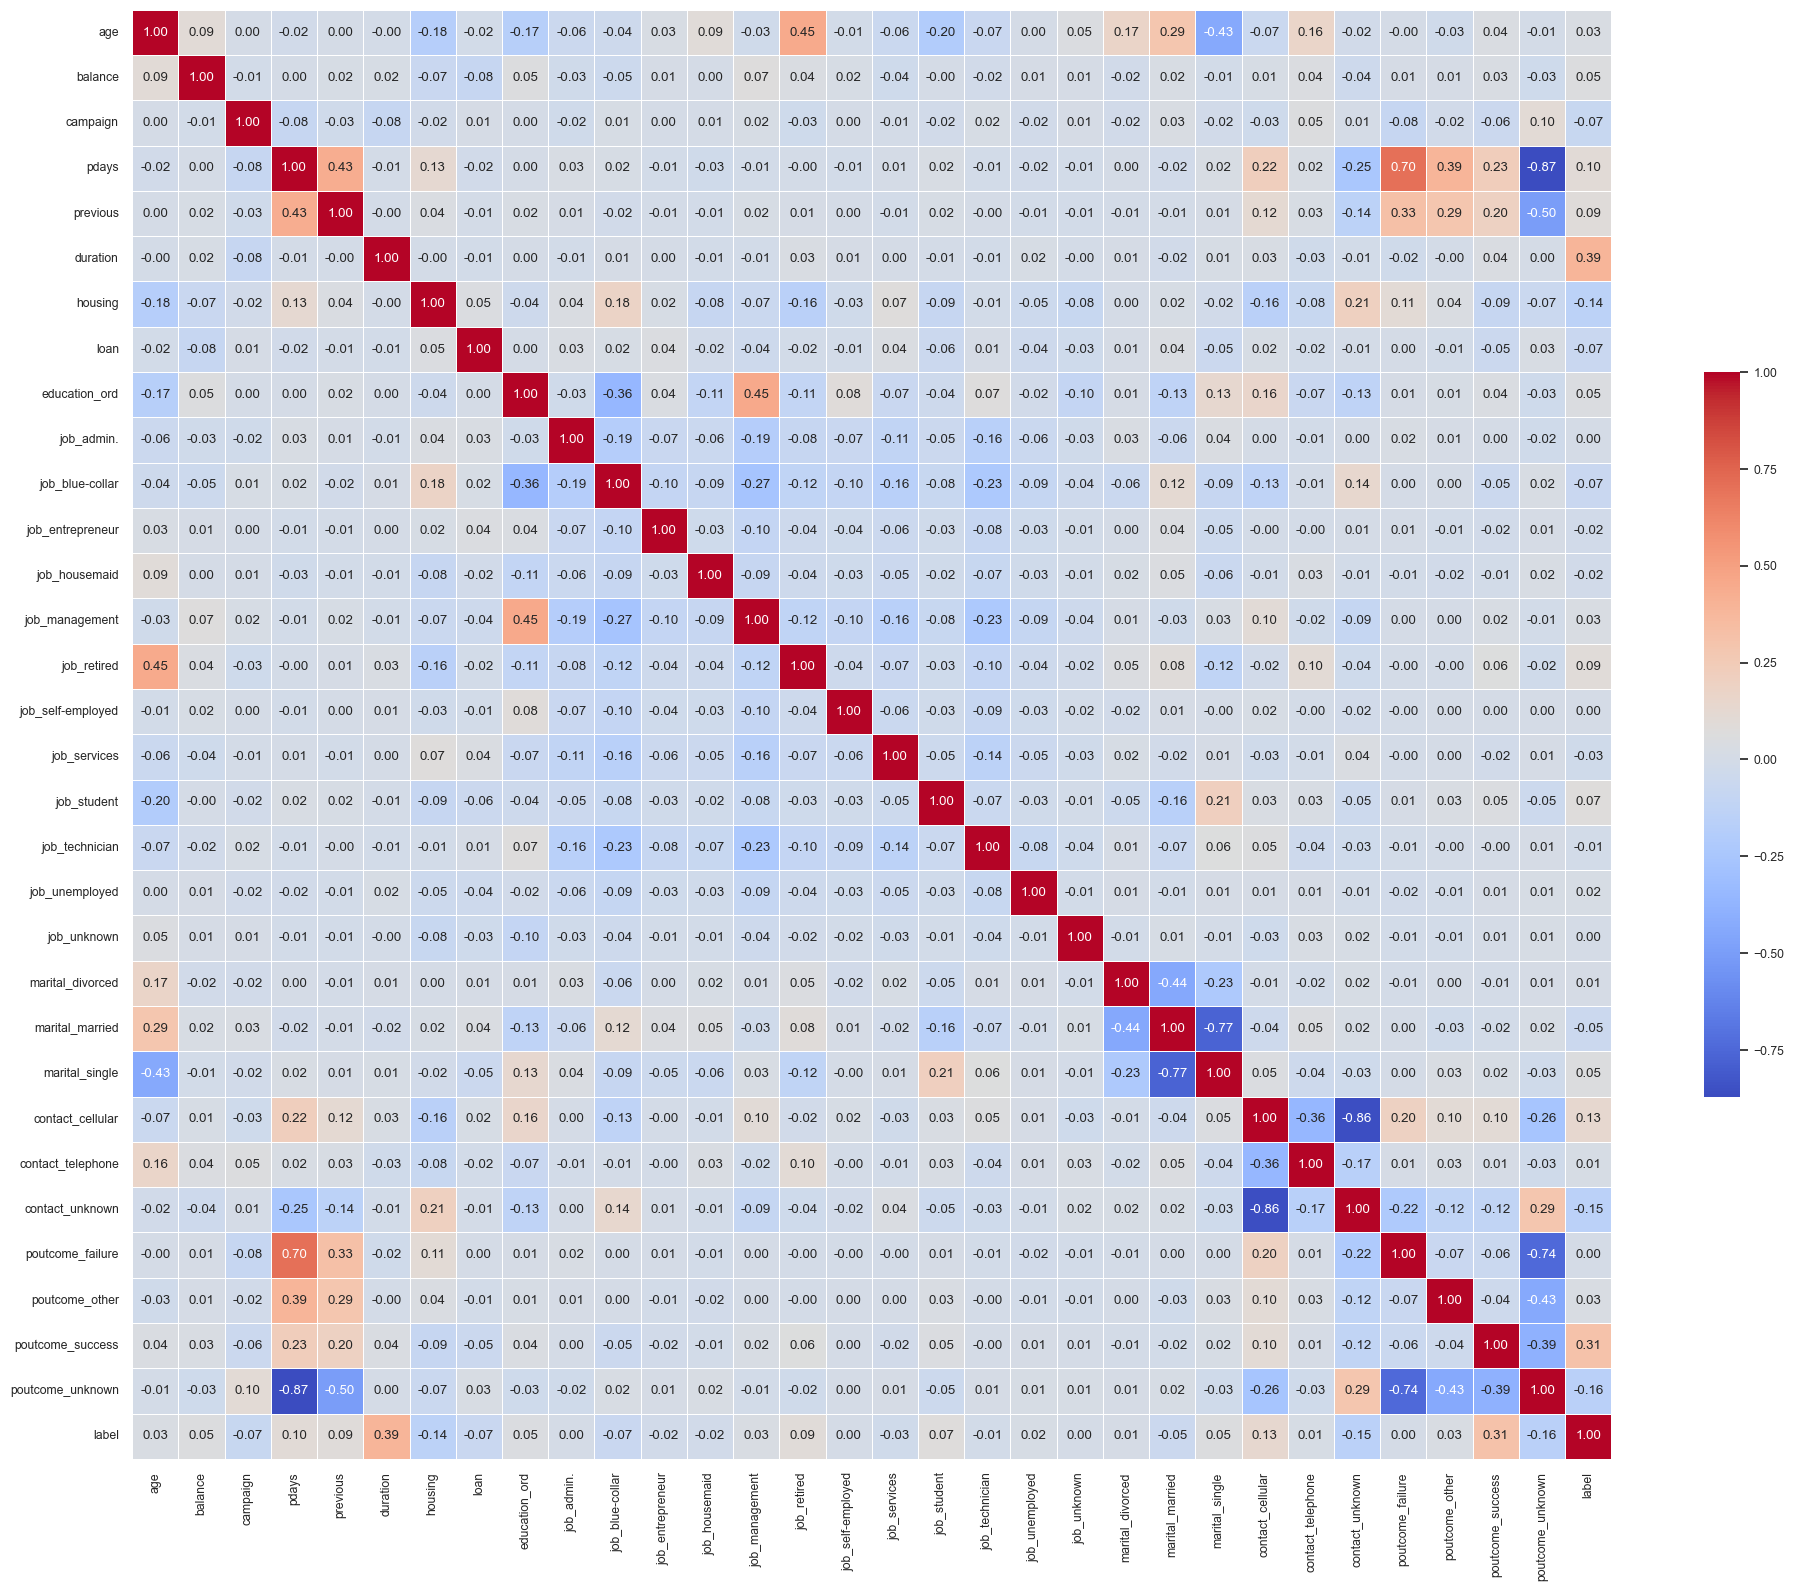

In [35]:
# job, marital, contact, poutcome 은 순서가 없으니 전부 더미(0/1) 변수로 분리
df_dummies = pd.get_dummies(
    data[['job','marital','contact','poutcome']],
    drop_first=False,   
    prefix_sep='_'
)

edu_map = {'unknown':0, 'primary':1, 'secondary':2, 'tertiary':3}
data['education_ord'] = data['education'].map(edu_map)

df_num = data[['age','balance','campaign','pdays','previous','duration']]
df_bin = data[['housing','loan']].replace({'no':0,'yes':1})

y_col = data[['label']]

df_corr = pd.concat([df_num, df_bin, data[['education_ord']], df_dummies, y_col], axis=1)
corr = df_corr.corr()

# 2) 사이즈와 폰트 스케일 조정
plt.figure(figsize=(20, 16))        
sns.set(font_scale=0.8)             

# 3) heatmap 그리기
ax = sns.heatmap(
    corr,
    cmap='coolwarm',                
    annot=True,                     
    fmt='.2f',                      
    linewidths=0.5,                 
    cbar_kws={"shrink": .5}         
)

# 4) 축 레이블 회전 및 정렬
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,                    
    ha='center'                    
)
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,                     
    va='center'                     
)

plt.tight_layout()                  
plt.show()


In [36]:
from sklearn.base import BaseEstimator, TransformerMixin


In [37]:
class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, attribute_names):
        self.attribute_names = attribute_names
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.attribute_names]

In [38]:
# 사용자 정의 CategoricalEncoder
class CategoricalEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, encoding='onehot-dense', categories='auto', dtype=np.float64, handle_unknown='ignore'):
        self.encoding = encoding
        self.categories = categories
        self.dtype = dtype
        self.handle_unknown = handle_unknown

    def fit(self, X, y=None):
        from sklearn.utils import check_array
        from sklearn.preprocessing import LabelEncoder
        X = check_array(X, dtype=object, accept_sparse='csc', copy=True)
        n_samples, n_features = X.shape
        self._label_encoders_ = [LabelEncoder() for _ in range(n_features)]
        for i in range(n_features):
            Xi = X[:, i]
            le = self._label_encoders_[i]
            if self.categories == 'auto':
                le.fit(Xi)
            else:
                le.classes_ = np.array(sorted(self.categories[i]))
        self.categories_ = [le.classes_ for le in self._label_encoders_]
        return self

    def transform(self, X):
        from sklearn.utils import check_array
        X = check_array(X, dtype=object, accept_sparse='csc', copy=True)
        n_samples, n_features = X.shape
        X_int = np.zeros_like(X, dtype=int)
        mask = np.ones_like(X, dtype=bool)
        for i in range(n_features):
            valid = np.in1d(X[:, i], self.categories_[i])
            if not valid.all():
                if self.handle_unknown == 'error':
                    raise ValueError(f"Unknown categories in column {i}")
                X[~valid, i] = self.categories_[i][0]
            X_int[:, i] = self._label_encoders_[i].transform(X[:, i])
            mask[:, i] = valid
        if self.encoding == 'ordinal':
            return X_int.astype(self.dtype)
        # one-hot
        n_values = [cats.size for cats in self.categories_]
        indices = np.cumsum([0] + n_values)
        row_idx = np.repeat(np.arange(n_samples), n_features)[mask.ravel()]
        col_idx = (X_int + indices[:-1]).ravel()[mask.ravel()]
        data = np.ones_like(col_idx, dtype=self.dtype)
        mat = sparse.csr_matrix((data, (row_idx, col_idx)), shape=(n_samples, indices[-1]))
        if self.encoding == 'onehot-dense':
            return mat.toarray()
        return mat

# DataFrameSelector 정의
class DataFrameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns): self.columns = columns
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.columns].values

In [39]:
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous","duration"]
cat_cols = ["job", "education", "marital", "default", "housing", "loan", "contact", "month", "poutcome"]

# pipeline
def build_preprocessor(num_cols, cat_cols):
    num_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale',  StandardScaler())
    ])
    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='missing')),
        ('encode', CategoricalEncoder(encoding='onehot-dense',
                                      handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols)
    ])

preprocessor = build_preprocessor(num_cols, cat_cols)

In [42]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# 데이터 불러오기
train_data = pd.read_csv('train.csv')
test_data  = pd.read_csv('test.csv')

# 사용할 feature 컬럼만 골라서 넘기기
feature_cols = num_cols + cat_cols 
X_train_df = train_data[feature_cols]
X_test_df  = test_data[feature_cols]

# 레이블 분리
y_col = train_data['label']

# 4) 파이프라인으로 전처리
#    fit_transform 은 train 에만, transform 은 test 에만
X_train = preprocessor.fit_transform(X_train_df)
X_test  = preprocessor.transform(X_test_df)

/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xjvj0x4vj84g36qs961pg80000gn/T/ipykernel_33610/3131163131.py:32: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  valid = np.in1d(X[:, i], self.categories_[i])
/var/folders/_g/y6xj

In [44]:
from scipy import sparse

from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

In [45]:
gbm = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1,
                                 max_depth=5, random_state=42)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                    subsample=0.8, colsample_bytree=0.8,
                    use_label_encoder=False, eval_metric='logloss', random_state=42)
rf  = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)

# (3) 스태킹 앙상블
stack = StackingClassifier(
    estimators=[('gbm', gbm), ('xgb', xgb), ('rf', rf)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5, n_jobs=-1, passthrough=True
)

# (4) CV로 F1 평가
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
stack_scores = cross_val_score(stack, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)


[00:22:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:22] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:34] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:34] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

[00:22:34] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" }

In [ ]:
print(f"Stacking CV F1: {stack_scores.mean():.4f} ± {stack_scores.std():.4f}")